# 02 · Validação do DEM real (Copernicus GLO-30)

Verificamos o recorte versionado em `sample_data/`, a consistência geométrica (tamanho de célula, área por pixels × área do polígono) e, **se houver rede**, se o recorte é idêntico ao tile ao vivo da AWS.

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ.setdefault("TSI_MODE", "demo")
sys.path.insert(0, str(ROOT / "backend"))
warnings.filterwarnings("ignore")
import numpy as np, rasterio, matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from rasterio.transform import from_origin
from app.core import terrain, dem as demmod, soil as soilmod, zonal, geometry as geom, contours
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
with rasterio.open(ROOT / "sample_data/demo_dem_glo30.tif") as s:
    DEM, TR = s.read(1), s.transform


## 1. Metadados e estatísticas do recorte

CRS: EPSG:4326 | shape: (433, 433) | dtype: float32 | nodata: nan
bounds: (-46.84014, -22.26014, -46.71986, -22.13986)
tags: {'TSI_BBOX': '(-46.84, -22.26, -46.72, -22.14)', 'TSI_RETRIEVED_AT': '2026-10-31T16:16:19+00:00', 'TSI_SOURCE': 'Copernicus DEM GLO-30 via AWS Open Data', 'TSI_TILES': 'https://copernicus-dem-30m.s3.amazonaws.com/Copernicus_DSM_COG_10_S23_', 'AREA_OR_POINT': 'Area'}

NaN: 0 · min/média/máx (m): 663.3 837.4 1106.3
célula: 28.64 m (E–O) × 30.76 m (N–S) a -22.20°


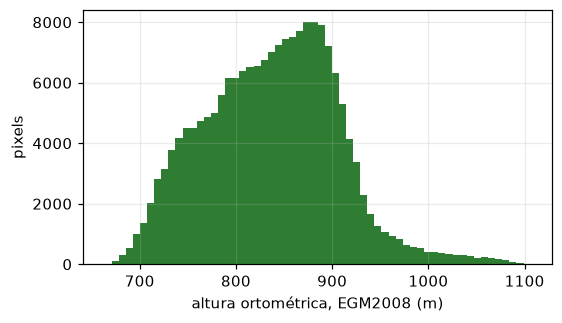

In [2]:
with rasterio.open(ROOT / "sample_data/demo_dem_glo30.tif") as s:
    print("CRS:", s.crs, "| shape:", s.shape, "| dtype:", s.dtypes[0], "| nodata:", s.nodata)
    print("bounds:", tuple(round(v, 5) for v in s.bounds))
    print("tags:", {k: v[:70] for k, v in s.tags().items()})
print("\nNaN:", int(np.isnan(DEM).sum()), "· min/média/máx (m):", np.nanmin(DEM).round(1), np.nanmean(DEM).round(1), np.nanmax(DEM).round(1))
dx, dy = terrain.cell_size_m(TR, DEM.shape[0])
print(f"célula: {dx.mean():.2f} m (E–O) × {dy.mean():.2f} m (N–S) a {TR.f + TR.e*DEM.shape[0]/2:.2f}°")
plt.figure(figsize=(5.5, 3)); plt.hist(DEM.ravel(), 60, color="#2e7d32"); plt.xlabel("altura ortométrica, EGM2008 (m)"); plt.ylabel("pixels"); plt.show()

**Observação sobre o datum:** as alturas são **ortométricas (EGM2008)**, isto é, referidas ao geoide, não ao elipsoide WGS 84. Comparar com altitudes GNSS elipsoidais exige subtrair a ondulação geoidal (N), da ordem de metros no Sudeste do Brasil (valor não calculado aqui).

## 2. Consistência: pixels × área do polígono

In [3]:
gj = json.loads((ROOT / "sample_data/propriedade_demo.geojson").read_text())
prop = [f for f in gj["features"] if f["properties"]["kind"] == "property"][0]["geometry"]
P = geom.validate_geometry(prop).geometry
m = geom.metrics(P)
sl, asp = terrain.slope_aspect(DEM, TR)
mask = zonal.cell_mask(P, TR, DEM.shape)
cell_ha = (dx.mean()*dy.mean())/1e4
print(f"polígono: {m['area_ha']:.2f} ha (UTM) · {m['area_ha_geodesic']:.2f} ha (geodésica)")
print(f"pixels no polígono: {int(mask.sum())} × {cell_ha:.4f} ha = {mask.sum()*cell_ha:.2f} ha → razão {mask.sum()*cell_ha/m['area_ha']:.4f}")
print("Quanto menor o polígono, maior o erro de borda: talhão D (1,8 ha):")
D = [f for f in gj["features"] if f["properties"]["name"].startswith("Talhão D")][0]["geometry"]
Dg = geom.validate_geometry(D).geometry; dm = geom.metrics(Dg); mk = zonal.cell_mask(Dg, TR, DEM.shape)
print(f"  {dm['area_ha']:.2f} ha vs {mk.sum()} pixels × {cell_ha:.4f} = {mk.sum()*cell_ha:.2f} ha (razão {mk.sum()*cell_ha/dm['area_ha']:.2f})")

polígono: 332.86 ha (UTM) · 332.85 ha (geodésica)
pixels no polígono: 3775 × 0.0881 ha = 332.60 ha → razão 0.9992
Quanto menor o polígono, maior o erro de borda: talhão D (1,8 ha):
  1.78 ha vs 16 pixels × 0.0881 = 1.41 ha (razão 0.79)


## 3. Consistência de aspecto × sombreamento

O relevo sombreado com sol a NO (azimute 315°) deve ser mais claro onde a encosta *olha* para NO. Correlação positiva entre iluminação e proximidade do aspecto a 315° confirma a convenção de aspecto (azimute da descida).

In [4]:
hs = terrain.hillshade(DEM, TR)
ok = np.isfinite(asp) & np.isfinite(hs) & (terrain.slope_pct(sl) > 10)
closeness = np.cos(np.radians(asp[ok] - 315))
print("correlação (iluminação × cos(aspecto − 315°)) em encostas > 10%:", np.corrcoef(hs[ok], closeness)[0, 1].round(3))

correlação (iluminação × cos(aspecto − 315°)) em encostas > 10%: 0.919


## 4. DEM ao vivo × recorte versionado (opcional, precisa de internet)

In [5]:
if os.environ.get("TSI_RUN_NETWORK") == "1" or True:
    try:
        bbox = (-46.80, -22.22, -46.76, -22.18)
        live = demmod.fetch_live(bbox)
        with rasterio.open(ROOT / "sample_data/demo_dem_glo30.tif") as s:
            arr, _ = demmod.read_window(s, bbox)
        print("shape ao vivo:", live.array.shape, "· amostra:", arr.shape, "· idênticos:", bool(np.allclose(live.array, arr, equal_nan=True)))
        print("recuperado em:", live.meta["retrieved_at"], "\nfonte:", live.meta["source"])
    except Exception as e:
        print("Sem rede/fonte indisponível, comparação ao vivo PULADA:", repr(e)[:120])

shape ao vivo: (145, 145) · amostra: (145, 145) · idênticos: True
recuperado em: 2026-10-31T16:45:07+00:00 
fonte: https://copernicus-dem-30m.s3.amazonaws.com/Copernicus_DSM_COG_10_S23_00_W047_00_DEM/Copernicus_DSM_COG_10_S23_00_W047_00_DEM.tif


## Conclusões

- O recorte é um DSM real (663–1106 m), sem lacunas, em EPSG:4326 com células de ≈ 28,6 × 30,8 m. A fonte marca `AREA_OR_POINT=Point`; usamos a geotransformação do arquivo (limites a meio pixel de graus inteiros), então pode haver uma ambiguidade posicional de até meio pixel (~15 m) que não verificamos.
- A soma de pixels reproduz a área da propriedade (razão 0,999); no talhão de 1,8 ha os 16 pixels cobrem só 79% da área, razão do aviso de 'poucos pixels'.
- A convenção de aspecto é consistente com o sombreamento (correlação 0,92 em encostas > 10%).
- O recorte versionado é idêntico ao tile ao vivo (verificado em 31/10/2026).
- **Limite:** nada aqui mede a exatidão do DEM contra o terreno.